# Variable selection bias and importance scores

Exhaustive-search trees such as CART favor variables with many distinct values: such a variable offers more cutpoints, so by chance alone one of them is more likely to reduce impurity. GUIDE avoids this bias by choosing the split variable with chi-square tests, whose p-values put variables with different numbers of values on a common scale.

This matters most for interpretation: a tree's split variables, and importance scores built from them, can point to noise. This notebook shows the effect with a null simulation and then compares importance scores on the diabetes data with added noise variables.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chisquare
from sklearn.datasets import load_diabetes
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

from guide_rs import GuideRegressor, importance

## A null simulation

Five predictors, all independent of the response, differ only in their number of distinct values: 2, 5, 10, 50 and continuous. In each of 500 replications we fit a single split (a stump) with each method and record the variable it splits on. With no bias, each variable should be chosen about 20% of the time.

In [2]:
rng = np.random.default_rng(0)
values = {"binary": 2, "5 values": 5, "10 values": 10, "50 values": 50, "continuous": None}
n, reps = 200, 500
chosen = {"GUIDE": [], "CART": []}
for _ in range(reps):
    X = pd.DataFrame({
        name: rng.normal(size=n) if k is None else rng.integers(0, k, n).astype(float)
        for name, k in values.items()
    })
    y = rng.normal(size=n)
    guide = GuideRegressor(max_depth=1, pruning="none", min_gain=0).fit(X, y)
    root = json.loads(guide.to_json())["trees"][0]["root"]
    chosen["GUIDE"].append(X.columns[root["split"]["feature"]])
    cart = DecisionTreeRegressor(max_depth=1).fit(X, y)
    chosen["CART"].append(X.columns[cart.tree_.feature[0]])

counts = pd.DataFrame({m: pd.Series(c).value_counts().reindex(list(values), fill_value=0)
                       for m, c in chosen.items()})
counts / reps

,GUIDE,CART
binary,0.230,0.026
5 values,0.154,0.070
10 values,0.206,0.112
50 values,0.206,0.316
continuous,0.204,0.476


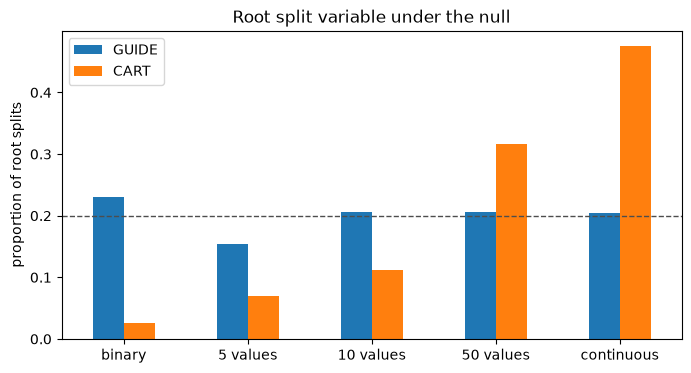

GUIDE: chi-square test of uniform selection, p = 0.101
CART: chi-square test of uniform selection, p = 6.12e-77


In [3]:
ax = (counts / reps).plot.bar(figsize=(8, 4), rot=0)
ax.axhline(0.2, color="0.3", ls="--", lw=1)
ax.set(ylabel="proportion of root splits", title="Root split variable under the null")
plt.show()
for method in counts:
    print(f"{method}: chi-square test of uniform selection, p = {chisquare(counts[method]).pvalue:.3g}")

CART almost always splits on the continuous or 50-value variable and rarely on the binary one. GUIDE's choices are consistent with uniform selection.

## Importance scores with noise variables

Next, the diabetes data plus three noise variables: a continuous one, a binary one, and a 40-level categorical "clinic" code. We compare:

- **GUIDE importance** (`guide_rs.importance`, Loh and Zhou 2021): scores from GUIDE's selection statistics, adjusted by their mean under permutations of the response, with a threshold separating important from unimportant variables.
- **Random forest impurity importance** (`feature_importances_`), which inherits CART's selection bias.
- **Permutation importance** of the random forest on a held-out 30% of the data, scikit-learn's recommended alternative to impurity importance.

In [4]:
X, y = load_diabetes(return_X_y=True, as_frame=True)
rng = np.random.default_rng(1)
X["noise continuous"] = rng.normal(size=len(X))
X["noise binary"] = rng.integers(0, 2, len(X)).astype(float)
clinic = rng.integers(0, 40, len(X))
X_guide = X.assign(clinic=pd.Categorical(clinic.astype(str)))  # GUIDE: categorical
X_sklearn = X.assign(clinic=clinic.astype(float))  # scikit-learn: integer codes

report = importance(GuideRegressor(), X_guide, y)
guide_scores = pd.DataFrame(report["scores"]).set_index("feature")

X_train, X_test, y_train, y_test = train_test_split(X_sklearn, y, test_size=0.3, random_state=0)
forest = RandomForestRegressor(n_estimators=300, random_state=0).fit(X_train, y_train)
permuted = permutation_importance(forest, X_test, y_test, n_repeats=20, random_state=0)

table = pd.DataFrame({
    "GUIDE adjusted": guide_scores["adjusted_score"],
    "GUIDE group": guide_scores["group"],
    "RF impurity": pd.Series(forest.feature_importances_, X_sklearn.columns),
    "RF permutation": pd.Series(permuted.importances_mean, X_sklearn.columns),
})
ranks = table[["GUIDE adjusted", "RF impurity", "RF permutation"]].rank(ascending=False)
table.join(ranks.add_suffix(" rank").astype(int)).sort_values("GUIDE adjusted", ascending=False).round(3)

,GUIDE adjusted,GUIDE group,RF impurity,RF permutation,GUIDE adjusted rank,RF impurity rank,RF permutation rank
s5,19.246,highly_important,0.290,0.177,1,2,1
bmi,18.340,highly_important,0.292,0.160,2,1,2
bp,12.331,highly_important,0.087,0.037,3,3,3
s4,9.406,highly_important,0.024,-0.007,4,11,11
s6,9.228,highly_important,0.044,0.004,5,6,6
s3,8.990,highly_important,0.054,-0.015,6,4,13
noise binary,2.894,unimportant,0.008,0.009,7,12,4
s1,2.718,unimportant,0.034,-0.002,8,10,9
s2,2.700,unimportant,0.038,-0.001,9,8,8
sex,2.698,unimportant,0.007,0.002,10,13,7


GUIDE places all three noise variables in its unimportant group. The random forest's impurity importance ranks the continuous noise and the 40-level clinic code above several real variables, while the binary noise variable, with a single possible cutpoint, ranks near the bottom: the same bias as in the simulation.

Held-out permutation importance has no such bias, but beyond the three strongest variables its values are small and noisy; here the binary noise variable ranks fourth by chance.